In [1]:
import numpy as np
%matplotlib widget
import matplotlib.pyplot as plt
from plt_overfit import overfit_example, output
from lab_utils_common import sigmoid
np.set_printoptions(precision=8)

In [2]:
#Cost function for regularized linear regression
def compute_cost_linear_reg(X,y,w,b,lambda_=1):
     """
    Computes the cost over all examples
    Args:
      X (ndarray (m,n): Data, m examples with n features
      y (ndarray (m,)): target values
      w (ndarray (n,)): model parameters  
      b (scalar)      : model parameter
      lambda_ (scalar): Controls amount of regularization
    Returns:
      total_cost (scalar):  cost 
    """
     m = X.shape[0]
     n = len(w)
     cost = 0
     for i in range(m):
          f_wb_i = np.dot(X[i],w) + b
          cost = cost +(f_wb_i - y[i])**2
     cost = cost / (2*m)

     reg_cost = 0
     for j in range(n):
          reg_cost = reg_cost + (w[j]**2)
     reg_cost = (lambda_/(2*m))*reg_cost

     total_cost = cost + reg_cost
     return total_cost


In [3]:
np.random.seed(1)
X_tmp = np.random.rand(5,6)
y_tmp = np.array([0,1,0,1,0])
w_tmp = np.random.rand(X_tmp.shape[1]).reshape(-1)-0.5
b_tmp = 0.5
lambda_tmp = 0.7
cost_tmp = compute_cost_linear_reg(X_tmp, y_tmp, w_tmp, b_tmp, lambda_tmp)

print("Regularized cost:", cost_tmp)

Regularized cost: 0.07917239320214277


In [4]:
#Cost function for logistic regression
def compute_cost_logistic_reg(X, y, w, b, lambda_ = 1):
    """
    Computes the cost over all examples
    Args:
    Args:
      X (ndarray (m,n): Data, m examples with n features
      y (ndarray (m,)): target values
      w (ndarray (n,)): model parameters  
      b (scalar)      : model parameter
      lambda_ (scalar): Controls amount of regularization
    Returns:
      total_cost (scalar):  cost 
    """
    m, n = X.shape
    cost = 0
    for i in range(m):
        z_i = np.dot(X[i], w) +b
        f_wb_i = sigmoid(z_i)
        cost = cost - y[i]*np.log(f_wb_i)-(1-y[i])*np.log(1-f_wb_i)

    cost = cost/m
    reg_cost = 0
    for j in range(n):
        reg_cost = reg_cost+ (w[j]**2)
    reg_cost = (lambda_/(2*m))*reg_cost

    total_cost = cost + reg_cost
    return total_cost



In [5]:
np.random.seed(1)
X_tmp = np.random.rand(5,6)
y_tmp = np.array([0,1,0,1,0])
w_tmp = np.random.rand(X_tmp.shape[1]).reshape(-1)-0.5
b_tmp = 0.5
lambda_tmp = 0.7
cost_tmp = compute_cost_logistic_reg(X_tmp, y_tmp, w_tmp, b_tmp, lambda_tmp)

print("Regularized cost:", cost_tmp)

Regularized cost: 0.6850849138741673


In [6]:
#Gradient function for regularized linear regression
def compute_gradient_linear_reg(X,y,w,b,lambda_):
   """
    Computes the gradient for linear regression 
    Args:
      X (ndarray (m,n): Data, m examples with n features
      y (ndarray (m,)): target values
      w (ndarray (n,)): model parameters  
      b (scalar)      : model parameter
      lambda_ (scalar): Controls amount of regularization
      
    Returns:
      dj_dw (ndarray (n,)): The gradient of the cost w.r.t. the parameters w. 
      dj_db (scalar):       The gradient of the cost w.r.t. the parameter b. 
    """
   m, n = X.shape
   dj_dw = np.zeros((n,))
   dj_db = 0

   for i in range(m):
      err = (np.dot(X[i],w) + b)- y[i]
      for j in range(n):
         dj_dw[j] = dj_dw[j]+ err*X[i,j]
      dj_db = dj_db +err
   dj_dw = dj_dw/m
   dj_db = dj_db/m

   for j in range(n):
      dj_dw[j] = dj_dw[j] + (lambda_/m)*w[j]

   return dj_db, dj_dw   
    

In [7]:
np.random.seed(1)
X_tmp = np.random.rand(5,3)
y_tmp = np.array([0,1,0,1,0])
w_tmp = np.random.rand(X_tmp.shape[1])
b_tmp = 0.5
lambda_tmp = 0.7
dj_db_tmp, dj_dw_tmp =  compute_gradient_linear_reg(X_tmp, y_tmp, w_tmp, b_tmp, lambda_tmp)

print(f"dj_db: {dj_db_tmp}", )
print(f"Regularized dj_dw:\n {dj_dw_tmp.tolist()}", )

dj_db: 0.6648774569425726
Regularized dj_dw:
 [0.29653214748822276, 0.4911679625918033, 0.21645877535865857]


In [12]:
#Gradient function for regularized logiistic regression
def compute_gradient_logistic_reg(X,y,w,b,lambda_):
   """
    Computes the gradient for linear regression 
    Args:
      X (ndarray (m,n): Data, m examples with n features
      y (ndarray (m,)): target values
      w (ndarray (n,)): model parameters  
      b (scalar)      : model parameter
      lambda_ (scalar): Controls amount of regularization
      
    Returns:
      dj_dw (ndarray (n,)): The gradient of the cost w.r.t. the parameters w. 
      dj_db (scalar):       The gradient of the cost w.r.t. the parameter b. 
    """
   m, n = X.shape
   dj_dw = np.zeros((n,))
   dj_db = 0

   for i in range(m):
      f_wb_i = sigmoid(np.dot(X[i],w) + b)
      err = f_wb_i- y[i]
      for j in range(n):
         dj_dw[j] = dj_dw[j]+ err*X[i,j]
      dj_db = dj_db +err
   dj_dw = dj_dw/m
   dj_db = dj_db/m

   for j in range(n):
      dj_dw[j] = dj_dw[j] + (lambda_/m)*w[j]

   return dj_db, dj_dw   
    

In [13]:
np.random.seed(1)
X_tmp = np.random.rand(5,3)
y_tmp = np.array([0,1,0,1,0])
w_tmp = np.random.rand(X_tmp.shape[1])
b_tmp = 0.5
lambda_tmp = 0.7
dj_db_tmp, dj_dw_tmp =  compute_gradient_logistic_reg(X_tmp, y_tmp, w_tmp, b_tmp, lambda_tmp)

print(f"dj_db: {dj_db_tmp}", )
print(f"Regularized dj_dw:\n {dj_dw_tmp.tolist()}", )

dj_db: 0.341798994972791
Regularized dj_dw:
 [0.17380012933994293, 0.32007507881566943, 0.10776313396851499]


Output()

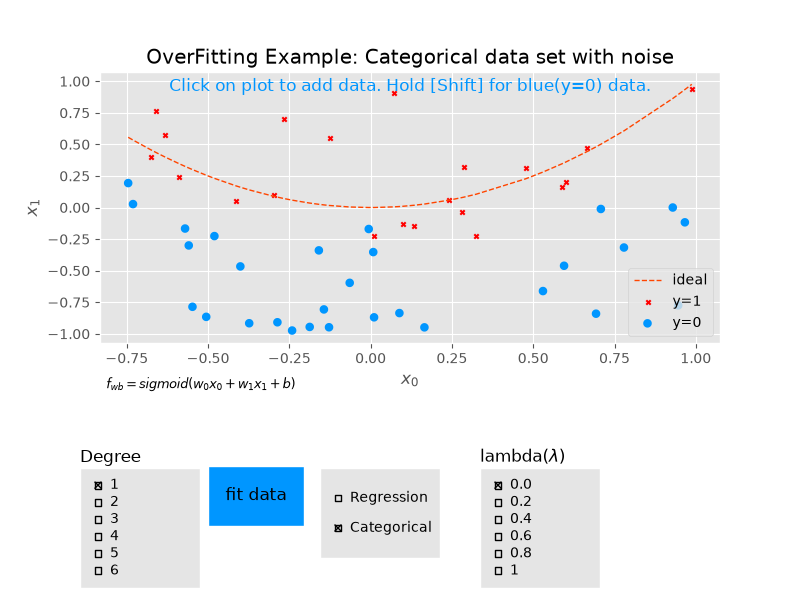

In [14]:
plt.close("all")
display(output)
ofit = overfit_example(True)